In [2]:
import os, re, json, random, math, time
from collections import Counter, defaultdict

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU not detected. In Kaggle, open Settings > Accelerator > GPU.")

PyTorch: 2.11.0+cu128
Device: cuda
GPU: Tesla T4


In [3]:
BASE_DIR = "/kaggle/input/datasets/nagasai524/mini-coco2014-dataset-for-image-captioning"
CAPTION_FILE = os.path.join(BASE_DIR, "captions.json")
IMAGE_DIR = os.path.join(BASE_DIR, "Images")

if not os.path.isfile(CAPTION_FILE):
    raise FileNotFoundError(f"Cannot find captions.json at {CAPTION_FILE}. Check the Kaggle dataset path.")
if not os.path.isdir(IMAGE_DIR):
    raise FileNotFoundError(f"Cannot find Images folder at {IMAGE_DIR}. Check the Kaggle dataset path.")

with open(CAPTION_FILE, "r", encoding="utf-8") as f:
    caption_records = json.load(f)

image_captions = defaultdict(list)
for item in caption_records:
    image_captions[int(item["image_id"])].append(item["caption"].strip())

image_paths = {}
for filename in os.listdir(IMAGE_DIR):
    if filename.lower().endswith((".jpg", ".jpeg", ".png")):
        match = re.search(r"(\d+)\.(?:jpg|jpeg|png)$", filename.lower())
        if match:
            image_paths[int(match.group(1))] = os.path.join(IMAGE_DIR, filename)

valid_image_ids = sorted(set(image_captions).intersection(image_paths))
if not valid_image_ids:
    raise RuntimeError("No image IDs matched captions.json to image filenames.")

random.shuffle(valid_image_ids)
split_at = int(0.9 * len(valid_image_ids))
train_ids = valid_image_ids[:split_at]
val_ids = valid_image_ids[split_at:]

print("Caption records:", len(caption_records))
print("Matched images:", len(valid_image_ids))
print("Train images:", len(train_ids))
print("Validation images:", len(val_ids))
print("Captions per first image:", len(image_captions[valid_image_ids[0]]))

Caption records: 93950
Matched images: 18783
Train images: 16904
Validation images: 1879
Captions per first image: 5


In [4]:
def tokenize(sentence):
    return re.findall(r"[a-z]+(?:'[a-z]+)?", sentence.lower())

MIN_FREQ = 5
MAX_LENGTH = 20
counter = Counter()
for image_id in train_ids:
    for caption in image_captions[image_id]:
        counter.update(tokenize(caption))

special_tokens = ["<PAD>", "<START>", "<END>", "<UNK>"]
word_to_idx = {token: i for i, token in enumerate(special_tokens)}
for word, freq in sorted(counter.items(), key=lambda item: (-item[1], item[0])):
    if freq >= MIN_FREQ and word not in word_to_idx:
        word_to_idx[word] = len(word_to_idx)
idx_to_word = {idx: word for word, idx in word_to_idx.items()}
VOCAB_SIZE = len(word_to_idx)
PAD_ID = word_to_idx["<PAD>"]
START_ID = word_to_idx["<START>"]
END_ID = word_to_idx["<END>"]
UNK_ID = word_to_idx["<UNK>"]

def encode_caption(caption):
    tokens = tokenize(caption)[:MAX_LENGTH - 2]
    tokens = ["<START>"] + tokens + ["<END>"]
    ids = [word_to_idx.get(token, UNK_ID) for token in tokens]
    ids += [PAD_ID] * (MAX_LENGTH - len(ids))
    return torch.tensor(ids[:MAX_LENGTH], dtype=torch.long)

print("Vocabulary size:", VOCAB_SIZE)
print("Example caption:", image_captions[train_ids[0]][0])
print("Encoded caption:", encode_caption(image_captions[train_ids[0]][0]).tolist())

Vocabulary size: 4338
Example caption: A group of people sitting on top of a green boat.
Encoded caption: [1, 4, 35, 6, 19, 14, 5, 33, 6, 4, 66, 148, 2, 0, 0, 0, 0, 0, 0, 0]


In [5]:
IMAGE_SIZE = 224
BATCH_SIZE_FEATURES = 32

image_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

class ImageOnlyDataset(Dataset):
    def __init__(self, ids):
        self.ids = ids
    def __len__(self):
        return len(self.ids)
    def __getitem__(self, index):
        image_id = self.ids[index]
        with Image.open(image_paths[image_id]) as im:
            image = image_transform(im.convert("RGB"))
        return image, image_id

# Load pretrained VGG16. Its parameters stay frozen.
weights = models.VGG16_Weights.DEFAULT
vgg = models.vgg16(weights=weights)
feature_extractor = nn.Sequential(vgg.features, vgg.avgpool, nn.Flatten(), *list(vgg.classifier.children())[:5])
for p in feature_extractor.parameters():
    p.requires_grad = False
feature_extractor = feature_extractor.to(device).eval()

feature_loader = DataLoader(
    ImageOnlyDataset(valid_image_ids),
    batch_size=BATCH_SIZE_FEATURES,
    shuffle=False,
    num_workers=2 if os.name != "nt" else 0,
    pin_memory=(device.type == "cuda")
)

feature_chunks = []
feature_ids = []
start_time = time.time()
with torch.inference_mode():
    for images, ids in tqdm(feature_loader, desc="Extracting VGG16 features"):
        images = images.to(device, non_blocking=True)
        feats = feature_extractor(images)  # [batch, 4096]
        feature_chunks.append(feats.cpu().float())
        feature_ids.extend(int(x) for x in ids)

features = torch.cat(feature_chunks, dim=0)
feature_index = {image_id: i for i, image_id in enumerate(feature_ids)}
print("Feature matrix:", tuple(features.shape))
print(f"Feature extraction time: {(time.time()-start_time)/60:.1f} minutes")

FEATURE_PATH = "/kaggle/working/mini_coco_vgg16_features.pt"
torch.save({"features": features, "image_ids": feature_ids}, FEATURE_PATH)
print("Feature cache saved:", FEATURE_PATH)

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:02<00:00, 227MB/s] 


Extracting VGG16 features:   0%|          | 0/587 [00:00<?, ?it/s]

Feature matrix: (18783, 4096)
Feature extraction time: 10.5 minutes
Feature cache saved: /kaggle/working/mini_coco_vgg16_features.pt


In [6]:
class FeatureCaptionDataset(Dataset):
    def __init__(self, ids):
        self.samples = [(image_id, caption)
                       for image_id in ids
                       for caption in image_captions[image_id]]
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, index):
        image_id, caption = self.samples[index]
        feature = features[feature_index[image_id]]
        return feature, encode_caption(caption)

BATCH_SIZE = 256  # decoder-only training is much lighter than CNN training
train_dataset = FeatureCaptionDataset(train_ids)
val_dataset = FeatureCaptionDataset(val_ids)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
print("Training caption pairs:", len(train_dataset))
print("Validation caption pairs:", len(val_dataset))

Training caption pairs: 84549
Validation caption pairs: 9401


In [7]:
class ShowAndTellDecoder(nn.Module):
    def __init__(self, feature_size, embed_size, hidden_size, vocab_size, dropout=0.3):
        super().__init__()
        self.image_projection = nn.Linear(feature_size, embed_size)
        self.word_embedding = nn.Embedding(vocab_size, embed_size, padding_idx=PAD_ID)
        self.lstm = nn.LSTM(input_size=embed_size, hidden_size=hidden_size, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.output = nn.Linear(hidden_size, vocab_size)

    def forward(self, image_features, captions):
        # Predict captions[:, 1:] from image + captions[:, 1:-1].
        image_token = self.image_projection(image_features).unsqueeze(1)
        previous_word_embeddings = self.word_embedding(captions[:, 1:-1])
        lstm_inputs = torch.cat([image_token, previous_word_embeddings], dim=1)
        lstm_outputs, _ = self.lstm(lstm_inputs)
        return self.output(self.dropout(lstm_outputs))

    @torch.inference_mode()
    def generate(self, image_features, max_length=MAX_LENGTH):
        self.eval()
        image_token = self.image_projection(image_features).unsqueeze(1)
        h = None
        outputs, (h, c) = self.lstm(image_token)
        logits = self.output(outputs[:, -1, :])
        next_id = logits.argmax(dim=-1)
        result = []
        for _ in range(max_length - 1):
            token_id = int(next_id.item())
            if token_id == END_ID:
                break
            if token_id not in (PAD_ID, START_ID):
                result.append(idx_to_word.get(token_id, "<UNK>"))
            word_input = self.word_embedding(next_id).unsqueeze(1)
            outputs, (h, c) = self.lstm(word_input, (h, c))
            logits = self.output(outputs[:, -1, :])
            next_id = logits.argmax(dim=-1)
        return result

EMBED_SIZE = 512
HIDDEN_SIZE = 512
FEATURE_SIZE = int(features.shape[1])
model = ShowAndTellDecoder(FEATURE_SIZE, EMBED_SIZE, HIDDEN_SIZE, VOCAB_SIZE).to(device)
print(model)

# Sanity check: output sequence length must match captions[:, 1:].
example_features, example_captions = next(iter(train_loader))
with torch.no_grad():
    test_logits = model(example_features.to(device), example_captions.to(device))
print("Feature batch:", example_features.shape)
print("Caption batch:", example_captions.shape)
print("Logits:", test_logits.shape, "Target:", example_captions[:, 1:].shape)
assert test_logits.shape[:2] == example_captions[:, 1:].shape

ShowAndTellDecoder(
  (image_projection): Linear(in_features=4096, out_features=512, bias=True)
  (word_embedding): Embedding(4338, 512, padding_idx=0)
  (lstm): LSTM(512, 512, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (output): Linear(in_features=512, out_features=4338, bias=True)
)
Feature batch: torch.Size([256, 4096])
Caption batch: torch.Size([256, 20])
Logits: torch.Size([256, 19, 4338]) Target: torch.Size([256, 19])


In [8]:
NUM_EPOCHS = 5
LEARNING_RATE = 1e-3
criterion = nn.CrossEntropyLoss(ignore_index=PAD_ID)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

BEST_PATH = "/kaggle/working/show_and_tell_pytorch_corrected.pth"
history = {"train_loss": [], "val_loss": []}
best_val_loss = float("inf")

for epoch in range(NUM_EPOCHS):
    model.train()
    train_total = 0.0
    train_batches = 0
    for batch_features, captions in tqdm(train_loader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS} train"):
        batch_features = batch_features.to(device, non_blocking=True)
        captions = captions.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(batch_features, captions)
        targets = captions[:, 1:]
        loss = criterion(logits.reshape(-1, VOCAB_SIZE), targets.reshape(-1))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        optimizer.step()
        train_total += loss.item()
        train_batches += 1

    train_loss = train_total / max(train_batches, 1)
    model.eval()
    val_total = 0.0
    val_batches = 0
    with torch.no_grad():
        for batch_features, captions in tqdm(val_loader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS} val", leave=False):
            batch_features = batch_features.to(device, non_blocking=True)
            captions = captions.to(device, non_blocking=True)
            logits = model(batch_features, captions)
            targets = captions[:, 1:]
            loss = criterion(logits.reshape(-1, VOCAB_SIZE), targets.reshape(-1))
            val_total += loss.item()
            val_batches += 1
    val_loss = val_total / max(val_batches, 1)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    print(f"Epoch {epoch+1}: train loss={train_loss:.4f} | validation loss={val_loss:.4f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save({
            "model_state_dict": model.state_dict(),
            "word_to_idx": word_to_idx,
            "idx_to_word": idx_to_word,
            "vocab_size": VOCAB_SIZE,
            "embed_size": EMBED_SIZE,
            "hidden_size": HIDDEN_SIZE,
            "max_length": MAX_LENGTH,
            "feature_size": FEATURE_SIZE,
            "history": history,
        }, BEST_PATH)
        print("Saved best checkpoint:", BEST_PATH)

print("Training complete. Best validation loss:", best_val_loss)

Epoch 1/5 train:   0%|          | 0/331 [00:00<?, ?it/s]

Epoch 1/5 val:   0%|          | 0/37 [00:00<?, ?it/s]

Epoch 1: train loss=3.9310 | validation loss=3.2486
Saved best checkpoint: /kaggle/working/show_and_tell_pytorch_corrected.pth


Epoch 2/5 train:   0%|          | 0/331 [00:00<?, ?it/s]

Epoch 2/5 val:   0%|          | 0/37 [00:00<?, ?it/s]

...

Epoch 4/5 val:   0%|          | 0/37 [00:00<?, ?it/s]

Epoch 4: train loss=2.6532 | validation loss=2.6615
Saved best checkpoint: /kaggle/working/show_and_tell_pytorch_corrected.pth


Epoch 5/5 train:   0%|          | 0/331 [00:00<?, ?it/s]

Epoch 5/5 val:   0%|          | 0/37 [00:00<?, ?it/s]

Epoch 5: train loss=2.5419 | validation loss=2.6166
Saved best checkpoint: /kaggle/working/show_and_tell_pytorch_corrected.pth
Training complete. Best validation loss: 2.6166327128539213


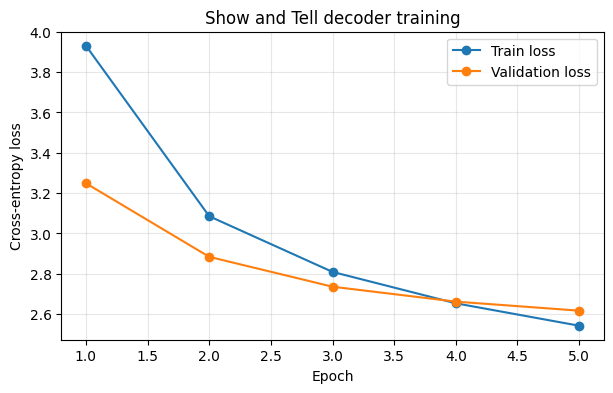

In [9]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(history["train_loss"])+1), history["train_loss"], marker="o", label="Train loss")
plt.plot(range(1, len(history["val_loss"])+1), history["val_loss"], marker="o", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Show and Tell decoder training")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

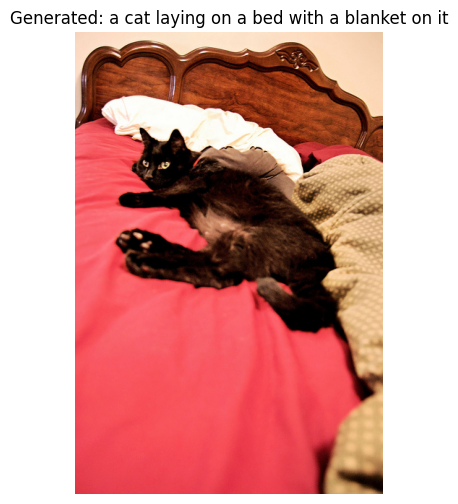

Image ID: 425470
Generated caption: a cat laying on a bed with a blanket on it
Reference captions:
- A cat laying comfortably on someone's bed with red sheets
- A large black cat rests in an unmade bed.
- A cat laying on a bed with a pink bed cover
- A black cat laying on top of a bed with a wooden headboard.
- This is an image of a cat on a bed.


In [10]:
# Reload best checkpoint for evaluation
checkpoint = torch.load(BEST_PATH, map_location=device, weights_only=False)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

image_id = val_ids[0]
image_path = image_paths[image_id]
with Image.open(image_path) as im:
    original_image = im.convert("RGB").copy()

feature = features[feature_index[image_id]].unsqueeze(0).to(device)
predicted_words = model.generate(feature)
predicted_caption = " ".join(predicted_words)

plt.figure(figsize=(9, 6))
plt.imshow(original_image)
plt.axis("off")
plt.title("Generated: " + (predicted_caption or "<empty caption>"))
plt.show()
print("Image ID:", image_id)
print("Generated caption:", predicted_caption)
print("Reference captions:")
for cap in image_captions[image_id]:
    print("-", cap)

In [11]:
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction

smooth = SmoothingFunction().method1
references = []
hypotheses = []
number_to_test = min(100, len(val_ids))

for image_id in tqdm(val_ids[:number_to_test], desc="BLEU evaluation"):
    feature = features[feature_index[image_id]].unsqueeze(0).to(device)
    predicted_words = model.generate(feature)
    reference_tokens = [tokenize(cap) for cap in image_captions[image_id]]
    references.append(reference_tokens)
    hypotheses.append(predicted_words)

    if len(hypotheses) <= 5:
        print("\nImage ID:", image_id)
        print("Generated:", " ".join(predicted_words))
        print("Reference:", image_captions[image_id][0])

for n in range(1, 5):
    weights = tuple((1.0 / n) if j < n else 0.0 for j in range(4))
    score = corpus_bleu(references, hypotheses, weights=weights, smoothing_function=smooth)
    print(f"BLEU-{n}: {score:.4f} ({score*100:.2f}%)")
print("Images evaluated:", number_to_test)

BLEU evaluation:   0%|          | 0/100 [00:00<?, ?it/s]


Image ID: 425470
Generated: a cat laying on a bed with a blanket on it
Reference: A cat laying comfortably on someone's bed with red sheets

Image ID: 114464
Generated: a large airplane flying through the sky above a cloudy sky
Reference: Near an amusement park ride, a plane flies high in the blue sky.

Image ID: 340673
Generated: a plate of food with a knife on it
Reference: A slice of chocolate cake and something to drink.

Image ID: 376972
Generated: a man riding a motorcycle down a street
Reference: A man riding on the back of a motor cycle.

Image ID: 18252
Generated: a person riding a motorcycle on a dirt road
Reference: A person that is doing a trick on a motorcycle.
BLEU-1: 0.6571 (65.71%)
BLEU-2: 0.4766 (47.66%)
BLEU-3: 0.3432 (34.32%)
BLEU-4: 0.2526 (25.26%)
Images evaluated: 100


In [12]:
print("Best model checkpoint:", BEST_PATH, os.path.getsize(BEST_PATH) // (1024*1024), "MB")
print("Feature cache:", FEATURE_PATH, os.path.getsize(FEATURE_PATH) // (1024*1024), "MB")
print("Vocabulary size:", VOCAB_SIZE)
print("Train images:", len(train_ids), "Validation images:", len(val_ids))

Best model checkpoint: /kaggle/working/show_and_tell_pytorch_corrected.pth 33 MB
Feature cache: /kaggle/working/mini_coco_vgg16_features.pt 293 MB
Vocabulary size: 4338
Train images: 16904 Validation images: 1879


In [13]:

import io
import torch
import ipywidgets as widgets
from IPython.display import display, clear_output
from PIL import Image

# Select an image from your computer
image_upload = widgets.FileUpload(
    accept="image/*",
    multiple=False,
    description="Choose Image"
)

output_area = widgets.Output()

def generate_uploaded_caption(change):
    if not image_upload.value:
        return

    with output_area:
        clear_output(wait=True)

        try:
            # Support different ipywidgets versions
            uploaded = image_upload.value

            if isinstance(uploaded, dict):
                file_info = next(iter(uploaded.values()))
            else:
                file_info = uploaded[0]

            image_bytes = bytes(file_info["content"])
            image = Image.open(io.BytesIO(image_bytes)).convert("RGB")

            # Display the image you selected
            display(image)

            # Apply the same preprocessing used during training
            image_tensor = image_transform(image).unsqueeze(0).to(device)

            # Extract VGG16 features and generate a caption
            feature_extractor.eval()
            model.eval()

            with torch.inference_mode():
                image_features = feature_extractor(image_tensor)
                predicted_words = model.generate(image_features)

            caption = " ".join(predicted_words)

            print("Generated Caption:")
            print(caption if caption else "No caption generated.")

        except Exception as error:
            print("Error:", error)

image_upload.observe(generate_uploaded_caption, names="value")

display(image_upload)
display(output_area)


FileUpload(value=(), accept='image/*', description='Choose Image')

Output()